# ESP32 on-device bird detector v2 (motion ROI → tight box → Pi crop)

This notebook trains the small detector that runs **on the ESP32**, so the Pi only ever receives a letterboxed bird crop instead of the whole scene.

## Pipeline this model is built for

1. **ESP32 motion check** (existing firmware) produces a rough motion box.
2. `square_roi()` turns the motion box into a square region of the full frame (expanded, minimum size, shifted inside the frame; anything still outside is padded with `PAD_VALUE`).
3. The region is resampled to `INPUT_SIZE × INPUT_SIZE` RGB with `reference_sample()` and fed to the int8 detector.
4. The best detection is mapped back to frame pixels, expanded by `PI_CROP_CONTEXT` per edge, cropped from the full-resolution frame and letterboxed to `PI_CROP_SIZE` with `make_pi_crop()`. Only that crop (JPEG) plus a small JSON goes to the Pi.

Every geometric step is defined once here in plain NumPy and written to `esp32_detector_contract.json` / `esp32_detector_contract.h`. The C++ firmware and the Pi-side isBird notebook must reproduce these functions exactly; section 4 checks that the TensorFlow training pipeline matches the NumPy reference.

## Data

`combined_annotations.csv` from `merge_esp32_datasets.py`: tight boxes in each image's own pixel space, `split_group` capture sessions, legacy 160×120 and current 640×480 frames.

- Training regions are **simulated motion ROIs**: bird-centred regions with random slack (motion boxes are never exact), random regions anywhere (mostly negatives), and whole-frame regions.
- Boxes that are tiny, mostly cut off by the region, or too small after resampling become **ignore** areas: they are neither positives nor negatives.
- Splits are by `split_group` (capture session) per source, so burst frames never leak between train / validation / test.

## Model

MobileNetV2 α=0.35 (ImageNet weights) truncated at `block_13_expand_relu` (stride 16 → 8×8 grid at 128 px), a separable-conv head, and two outputs: box `[1, G, G, A·4]` and score logits `[1, G, G, A]`. No reshape/sigmoid/NMS in the graph — decoding is a few lines of C. Full-integer export with uint8 input (raw RGB bytes), int8 outputs.

Run top to bottom. `QUICK_RUN = True` is only a pipeline check.

## 1. Configuration

In [1]:
# ---- Inputs ------------------------------------------------------------------
COMBINED_CSV = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Training Manifest\combined_annotations.csv"
# Searched (recursively, by file name) only when a row's stored image_path does not exist.
IMAGE_ROOTS = [
    r"E:\Datasets\ESP32_capture",
    r"C:\Users\Joe\Pictures\ESP32Cam",
]
OUTPUT_ROOT = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Multi_Object_Detector\runs"

# ---- Splits (by split_group, separately per source_dataset) ------------------
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15
# Sessions bigger than this are cut into time blocks so one long burst session
# cannot become the whole test set (e.g. a single 44-minute session holding half
# of the 640x480 data). Blocks are separated by a dropped buffer to limit leakage.
MAX_SESSION_IMAGES = 250
SESSION_BLOCK_MINUTES = 10
BLOCK_BUFFER_SECONDS = 60

# ---- Detector input / model --------------------------------------------------
INPUT_SIZE = 128            # 96 / 128 / 160. Grid = INPUT_SIZE / 16.
BACKBONE_ALPHA = 0.35
WEIGHTS = "imagenet"        # None trains from scratch.
FEATURE_LAYER = "block_13_expand_relu"   # stride 16
FEATURE_STRIDE = 16
NUM_ANCHORS = 3
HEAD_CHANNELS = 64
PAD_VALUE = 114             # value for pixels outside the frame (ROI and Pi letterbox)

# ---- Motion ROI contract (must match firmware) -------------------------------
ROI_EXPAND = 1.5            # square side = max(motion w, h) * ROI_EXPAND
ROI_MIN_SIDE_FRACTION = 0.25  # ... but at least this fraction of min(frame w, h)

# ---- Simulated motion boxes for training -------------------------------------
SAMPLE_MIX = {"bird_roi": 0.60, "random_roi": 0.30, "whole_frame": 0.10}
RANDOM_ROI_NO_BIRD_SHARE = 0.5     # random_roi draws this share from no_bird images
MOTION_SLACK_MAX = 1.0      # each motion-box edge grows by U(0, this) * bird size
MOTION_SHIFT_STD = 0.25     # motion-box centre shift, in bird sizes
MOTION_UNION_PROB = 0.2     # motion box covers every bird in the frame
RANDOM_ROI_SIZE = (0.05, 0.8)  # log-uniform motion box size, fraction of min(frame w, h)

# ---- Target rules --------------------------------------------------------------
MIN_BOX_PX = 4              # source boxes smaller than this per side become ignore areas
MIN_VISIBLE_FRACTION = 0.6  # less visible than this inside the ROI -> ignore area
MIN_TARGET_PX = 6           # boxes smaller than this after resampling -> ignore area

# ---- Training ------------------------------------------------------------------
BATCH_SIZE = 64
STEPS_PER_EPOCH = 500
HEAD_EPOCHS = 6
FINE_TUNE_EPOCHS = 60
HEAD_LR = 2e-3
FINE_TUNE_LR = 3e-4
EARLY_STOP_PATIENCE = 12    # validation loss is noisy; v1 stopped after 13 epochs
NEIGHBOUR_POSITIVES = True  # also assign each bird to the 2 nearest neighbouring cells
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0
BOX_LOSS_WEIGHT = 2.0
AUGMENT_COLOR = True
SEED = 1234

# ---- Decode / evaluation --------------------------------------------------------
CANDIDATE_SCORE_THRESHOLD = 0.05
NMS_IOU = 0.45
MAX_DETECTIONS = 5
MAX_FALSE_TRIGGER_RATE = 0.10  # threshold = best crop recall with at most this many empty ROIs firing
THRESHOLD_MODES = ("bird_roi", "random_roi")  # motion-ROI path only; whole_frame is reported, not tuned
CROP_COVERAGE_MIN = 0.9     # a bird is "captured" if this share of its box is inside the Pi crop
IOU_MATCH = 0.5             # reported alongside crop recall

# ---- Pi crop contract -----------------------------------------------------------
PI_CROP_CONTEXT = 0.25      # each edge grows by this fraction of the detected box size
PI_CROP_SIZE = 224

# ---- Export ---------------------------------------------------------------------
REPRESENTATIVE_SAMPLES = 400
TFLITE_EVAL_LIMIT = None    # None = every validation/test ROI

QUICK_RUN = False
if QUICK_RUN:
    STEPS_PER_EPOCH = 10
    HEAD_EPOCHS = 1
    FINE_TUNE_EPOCHS = 1
    EARLY_STOP_PATIENCE = 1
    REPRESENTATIVE_SAMPLES = 20
    TFLITE_EVAL_LIMIT = 120

assert INPUT_SIZE % FEATURE_STRIDE == 0
GRID = INPUT_SIZE // FEATURE_STRIDE
assert abs(sum(SAMPLE_MIX.values()) - 1) < 1e-9

## 2. Environment and helpers

In [2]:
import hashlib
import json
import math
import os
import platform
import random
import re
import time
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

keras = tf.keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def portable_path(raw_path):
    """Windows path <-> WSL /mnt/<drive> path, whichever this kernel needs."""
    raw = str(raw_path).strip()
    windows_path = PureWindowsPath(raw)
    if windows_path.drive:
        if os.name == "nt":
            return Path(raw)
        drive = windows_path.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows_path.parts[1:])
    mount = re.match(r"^/mnt/([A-Za-z])/(.*)$", raw.replace("\\", "/"))
    if mount and os.name == "nt":
        drive, rest = mount.groups()
        return Path(f"{drive.upper()}:/") / Path(*PurePosixPath(rest).parts)
    return Path(raw)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def parse_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "1.0", "yes"])


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


print("Python", platform.python_version(), "| TensorFlow", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793715217.408728     623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793715217.921360     623 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793715219.984411     623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.12.15 | TensorFlow 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load annotations, resolve images, split by session

One row per box in the CSV; this cell groups them into one record per image. Boxes under `MIN_BOX_PX` stay in the record as ignore areas, so a frame with a tiny bird is never treated as an empty scene.

In [3]:
COMBINED_CSV_PATH = portable_path(COMBINED_CSV)
ann = pd.read_csv(COMBINED_CSV_PATH, low_memory=False)
required = {"sample_id", "image_path", "relative_path", "width_px", "height_px", "review_state",
            "eligible_for_training", "xmin", "ymin", "xmax", "ymax", "split_group", "source_dataset"}
missing = required - set(ann.columns)
if missing:
    raise ValueError(f"combined CSV is missing {sorted(missing)}")

ann = ann[ann["review_state"].isin(["boxed", "no_bird"]) & parse_bool(ann["eligible_for_training"])].copy()
for column in ("xmin", "ymin", "xmax", "ymax", "width_px", "height_px"):
    ann[column] = pd.to_numeric(ann[column], errors="coerce")

# Images whose every row says no_bird are negatives; any boxed row makes it a bird image.
conflicting = ann.groupby("sample_id")["review_state"].nunique()
if (conflicting > 1).any():
    print(f"warning: {(conflicting > 1).sum()} images have both boxed and no_bird rows; treating them as boxed")

_index = None


def image_index():
    global _index
    if _index is None:
        _index = {}
        for root in IMAGE_ROOTS:
            root_path = portable_path(root)
            if not root_path.is_dir():
                print("image root not found, skipped:", root_path)
                continue
            for path in root_path.rglob("*"):
                if path.suffix.lower() in (".jpg", ".jpeg"):
                    _index.setdefault(path.name.lower(), path)
        print(f"indexed {len(_index):,} images under IMAGE_ROOTS")
    return _index


def resolve_image(stored, relative):
    direct = portable_path(stored) if isinstance(stored, str) and stored.strip() else None
    if direct is not None and direct.is_file():
        return str(direct)
    name = PurePosixPath(str(relative if isinstance(relative, str) else stored).replace("\\", "/")).name.lower()
    found = image_index().get(name)
    return str(found) if found else ""


records = []
for sample_id, rows in ann.groupby("sample_id", sort=True):
    first = rows.iloc[0]
    width, height = int(first["width_px"]), int(first["height_px"])
    boxed = rows[rows["review_state"].eq("boxed") & rows["xmin"].notna()]
    xyxy = boxed[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32)
    if len(xyxy):
        xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clip(0, width)
        xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clip(0, height)
    size_ok = ((xyxy[:, 2] - xyxy[:, 0]) >= MIN_BOX_PX) & ((xyxy[:, 3] - xyxy[:, 1]) >= MIN_BOX_PX) if len(xyxy) else np.zeros(0, bool)
    records.append({
        "sample_id": sample_id,
        "path": resolve_image(first["image_path"], first["relative_path"]),
        "width": width,
        "height": height,
        # source + resolution: the "legacy" export also contains 640x480 frames
        "source": f"{first['source_dataset']} {first['capture_config']}" if "capture_config" in rows else str(first["source_dataset"]),
        "group": str(first["split_group"]),
        "time": pd.to_datetime("".join(re.match(r"capture_(\d{8}T\d{6})_(\d{6})Z", sample_id).groups()),
                               format="%Y%m%dT%H%M%S%f") if re.match(r"capture_\d{8}T\d{6}_\d{6}Z", sample_id) else pd.NaT,
        "boxes": xyxy[size_ok],
        "ignore": xyxy[~size_ok],
        "has_bird": bool(len(xyxy)),
    })

unresolved = [r for r in records if not r["path"]]
if unresolved:
    print(f"{len(unresolved):,} images could not be found; examples:", [r["sample_id"] for r in unresolved[:5]])
    if len(unresolved) > 0.05 * len(records):
        raise FileNotFoundError("More than 5% of images are missing - fix IMAGE_ROOTS before training")
records = [r for r in records if r["path"]]


def block_large_sessions(records):
    """Cut oversized sessions into SESSION_BLOCK_MINUTES blocks; drop frames near block edges."""
    sizes = pd.Series([r["group"] for r in records]).value_counts()
    kept, dropped = [], 0
    for r in records:
        if sizes[r["group"]] <= MAX_SESSION_IMAGES or pd.isna(r["time"]):
            kept.append(r)
            continue
        seconds = r["time"].hour * 3600 + r["time"].minute * 60 + r["time"].second
        block, offset = divmod(seconds, SESSION_BLOCK_MINUTES * 60)
        if offset < BLOCK_BUFFER_SECONDS / 2 or offset > SESSION_BLOCK_MINUTES * 60 - BLOCK_BUFFER_SECONDS / 2:
            dropped += 1
            continue
        r["group"] = f"{r['group']}/{r['time']:%Y%m%d}_block{block:04d}"
        kept.append(r)
    print(f"split {int((sizes > MAX_SESSION_IMAGES).sum())} large sessions into time blocks; "
          f"dropped {dropped} frames in block-edge buffers")
    return kept


def assign_splits(records):
    """Whole groups go to one split; per source, fill test then validation without overshooting."""
    rng = np.random.default_rng(SEED)
    split_of_group = {}
    by_source = {}
    for r in records:
        by_source.setdefault(r["source"], {}).setdefault(r["group"], 0)
        by_source[r["source"]][r["group"]] += 1
    for source, groups in by_source.items():
        names = sorted(groups)
        rng.shuffle(names)
        total = sum(groups.values())
        targets = {"test": TEST_FRACTION * total, "validation": VAL_FRACTION * total}
        counts = {"test": 0, "validation": 0}
        for name in names:
            size = groups[name]
            split = "train"
            for candidate in ("test", "validation"):
                room = targets[candidate] - counts[candidate]
                # take the group if it fits, or if the split is still empty and the group is not huge
                if size <= room * 1.25 or (counts[candidate] == 0 and size <= 2 * targets[candidate]):
                    split = candidate
                    break
            split_of_group[(source, name)] = split
            if split != "train":
                counts[split] += size
    for r in records:
        r["split"] = split_of_group[(r["source"], r["group"])]


records = block_large_sessions(records)
assign_splits(records)
records_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("boxes", "ignore", "time")} | {
    "n_boxes": len(r["boxes"]), "n_ignore": len(r["ignore"])} for r in records])
display(pd.crosstab([records_df["split"], records_df["source"]], records_df["has_bird"], margins=True))
display(records_df.groupby("split")["group"].nunique().rename("sessions").to_frame())

train_records = [r for r in records if r["split"] == "train"]
val_records = [r for r in records if r["split"] == "validation"]
test_records = [r for r in records if r["split"] == "test"]
for name, subset in (("train", train_records), ("validation", val_records), ("test", test_records)):
    if not any(r["has_bird"] for r in subset) or all(r["has_bird"] for r in subset):
        print(f"warning: {name} split lacks bird or no-bird images; adjust fractions")

# Spot-check that decoded JPEG sizes match the CSV (geometry depends on it).
rng_check = np.random.default_rng(SEED)
for r in rng_check.choice(records, size=min(40, len(records)), replace=False):
    shape = tf.io.extract_jpeg_shape(tf.io.read_file(r["path"])).numpy()
    if (int(shape[1]), int(shape[0])) != (r["width"], r["height"]):
        raise ValueError(f"{r['path']}: JPEG is {shape[1]}x{shape[0]}, CSV says {r['width']}x{r['height']}")
print("JPEG sizes match the CSV on a 40-image spot check")

split 9 large sessions into time blocks; dropped 605 frames in block-edge buffers


has_bird                                 False  True   All
split      source                                         
test       esp32_legacy_160x120 160x120     19   138   157
           esp32_legacy_160x120 640x480    452   308   760
           image_directory 640x480         125   240   365
train      esp32_legacy_160x120 160x120    123   610   733
           esp32_legacy_160x120 640x480    902  2610  3512
           image_directory 640x480         451  1257  1708
validation esp32_legacy_160x120 160x120     54   103   157
           esp32_legacy_160x120 640x480    124   636   760
           image_directory 640x480          56   303   359
All                                       2306  6205  8511

,sessions
split,
test,24
train,82
validation,33


I0000 00:00:1793715292.960228     623 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


JPEG sizes match the CSV on a 40-image spot check


## 4. Geometry contract: motion ROI, resampling, Pi crop

These NumPy functions are the specification the firmware implements. Sampling uses pixel-centre alignment: output pixel `j` reads source `x = left + (j + 0.5) · side / out − 0.5`, bilinear, and any sample outside `[0, W−1] × [0, H−1]` becomes `PAD_VALUE`. TensorFlow's `crop_and_resize` reproduces this exactly with the box computed by `roi_to_crop_box`, which the check at the end of this cell confirms.

In [4]:
def square_roi(motion_box, frame_w, frame_h):
    """Motion box (l, t, r, b in frame pixels) -> square integer ROI (may extend past the frame)."""
    left, top, right, bottom = [float(v) for v in motion_box]
    cx, cy = (left + right) / 2.0, (top + bottom) / 2.0
    side = max(right - left, bottom - top) * ROI_EXPAND
    side = max(side, ROI_MIN_SIDE_FRACTION * min(frame_w, frame_h))
    side = min(side, max(frame_w, frame_h))
    side = max(1, int(round(side)))
    x0 = int(round(cx - side / 2.0))
    y0 = int(round(cy - side / 2.0))
    # Prefer real pixels over padding: slide inside the frame when it fits, else centre it.
    x0 = min(max(x0, 0), frame_w - side) if side <= frame_w else (frame_w - side) // 2
    y0 = min(max(y0, 0), frame_h - side) if side <= frame_h else (frame_h - side) // 2
    return (x0, y0, x0 + side, y0 + side)


def reference_sample(image, region, out_w, out_h, pad_value=PAD_VALUE):
    """Bilinear resample of region (l, t, r, b; floats allowed) to out_h x out_w. image: HxWx3 uint8."""
    height, width = image.shape[:2]
    left, top, right, bottom = [float(v) for v in region]
    xs = left + (np.arange(out_w) + 0.5) * (right - left) / out_w - 0.5
    ys = top + (np.arange(out_h) + 0.5) * (bottom - top) / out_h - 0.5
    gx, gy = np.meshgrid(xs, ys)
    inside = (gx >= 0) & (gx <= width - 1) & (gy >= 0) & (gy <= height - 1)
    x0 = np.clip(np.floor(gx), 0, width - 1).astype(int)
    y0 = np.clip(np.floor(gy), 0, height - 1).astype(int)
    x1 = np.clip(x0 + 1, 0, width - 1)
    y1 = np.clip(y0 + 1, 0, height - 1)
    fx = (gx - np.floor(gx))[..., None]
    fy = (gy - np.floor(gy))[..., None]
    img = image.astype(np.float32)
    top_row = img[y0, x0] * (1 - fx) + img[y0, x1] * fx
    bottom_row = img[y1, x0] * (1 - fx) + img[y1, x1] * fx
    out = top_row * (1 - fy) + bottom_row * fy
    out[~inside] = pad_value
    return out


def roi_to_crop_box(roi, frame_w, frame_h, out_size=INPUT_SIZE):
    """Normalized [y1, x1, y2, x2] so tf.image.crop_and_resize == reference_sample."""
    left, top, right, bottom = [float(v) for v in roi]
    sx, sy = (right - left) / out_size, (bottom - top) / out_size
    x_first, x_last = left + 0.5 * sx - 0.5, left + (out_size - 0.5) * sx - 0.5
    y_first, y_last = top + 0.5 * sy - 0.5, top + (out_size - 0.5) * sy - 0.5
    return np.array([y_first / max(frame_h - 1, 1), x_first / max(frame_w - 1, 1),
                     y_last / max(frame_h - 1, 1), x_last / max(frame_w - 1, 1)], np.float32)


def roi_box_to_frame(box_norm, roi):
    """Detector box (normalized to the ROI) -> frame pixels."""
    left, top, right, bottom = roi
    side = right - left
    x1, y1, x2, y2 = box_norm
    return np.array([left + x1 * side, top + y1 * side, left + x2 * side, top + y2 * side], np.float32)


def pi_crop_region(box_px, frame_w, frame_h, context=PI_CROP_CONTEXT):
    """Expand a frame-pixel box by `context` of its size on every edge, clip, round outward."""
    x1, y1, x2, y2 = [float(v) for v in box_px]
    w, h = x2 - x1, y2 - y1
    left = int(math.floor(max(0.0, x1 - context * w)))
    top = int(math.floor(max(0.0, y1 - context * h)))
    right = int(math.ceil(min(float(frame_w), x2 + context * w)))
    bottom = int(math.ceil(min(float(frame_h), y2 + context * h)))
    return (left, top, max(right, left + 1), max(bottom, top + 1))


def make_pi_crop(image, box_px, out_size=PI_CROP_SIZE, context=PI_CROP_CONTEXT, pad_value=PAD_VALUE):
    """What the ESP32 sends: context crop, aspect-preserving resize, centred on a pad canvas."""
    height, width = image.shape[:2]
    left, top, right, bottom = pi_crop_region(box_px, width, height, context)
    crop_w, crop_h = right - left, bottom - top
    scale = min(out_size / crop_w, out_size / crop_h)
    new_w = max(1, min(out_size, int(round(crop_w * scale))))
    new_h = max(1, min(out_size, int(round(crop_h * scale))))
    off_x, off_y = (out_size - new_w) // 2, (out_size - new_h) // 2
    canvas = np.full((out_size, out_size, 3), pad_value, np.float32)
    canvas[off_y:off_y + new_h, off_x:off_x + new_w] = reference_sample(image, (left, top, right, bottom), new_w, new_h)
    meta = {"crop_px": [left, top, right, bottom], "scale": scale, "offset": [off_x, off_y], "size": [new_w, new_h]}
    return np.clip(np.rint(canvas), 0, 255).astype(np.uint8), meta


def decode_rgb(path):
    return tf.io.decode_jpeg(tf.io.read_file(path), channels=3).numpy()


# --- verify TF sampling == reference, including regions that run off the frame ---
check = next(r for r in train_records if r["has_bird"]) if any(r["has_bird"] for r in train_records) else train_records[0]
frame = decode_rgb(check["path"])
H, W = frame.shape[:2]
worst = 0.0
for roi in [square_roi((0, 0, W, H), W, H), square_roi((W * 0.4, H * 0.4, W * 0.5, H * 0.55), W, H),
            (-W // 4, -H // 4, -W // 4 + int(W * 0.7), -H // 4 + int(W * 0.7)), (W // 3, H // 5, W // 3 + 37, H // 5 + 37)]:
    ref = reference_sample(frame, roi, INPUT_SIZE, INPUT_SIZE)
    tf_out = tf.image.crop_and_resize(tf.cast(frame, tf.float32)[None], roi_to_crop_box(roi, W, H)[None], [0],
                                      [INPUT_SIZE, INPUT_SIZE], method="bilinear", extrapolation_value=PAD_VALUE)[0].numpy()
    worst = max(worst, float(np.abs(ref - tf_out).max()))
print(f"max |reference - tf.crop_and_resize| = {worst:.4f} (0-255 scale)")
assert worst < 0.6, "TF pipeline does not match the reference sampler"

max |reference - tf.crop_and_resize| = 0.0020 (0-255 scale)


## 5. ROI sampling and target encoding

Grid slots follow the stride-16 detector contract you already use on the Pi: centre `= (sigmoid(tx)·3 − 1 + gx) / G`, size `= anchor · exp(clamp(tw, −4, 4))`, score `= sigmoid(logit)`. Each positive goes to its centre cell's best free anchor (and, with `NEIGHBOUR_POSITIVES`, to the two nearest neighbouring cells); every other slot whose cell centre lies inside a bird (or ignore area) is excluded from the negative loss.

In [5]:
def to_roi_norm(boxes_px, roi):
    left, top, right, _ = roi
    side = float(right - left)
    out = (boxes_px - np.array([left, top, left, top], np.float32)) / side
    return out.astype(np.float32)


def roi_targets_from_record(record, roi):
    """Split the record's boxes into positives / ignore areas for this ROI (normalized xyxy)."""
    positives, ignores = [], []
    side = roi[2] - roi[0]
    for box in to_roi_norm(record["boxes"], roi) if len(record["boxes"]) else []:
        area = max(1e-9, (box[2] - box[0]) * (box[3] - box[1]))
        clipped = np.clip(box, 0.0, 1.0)
        visible = max(0.0, clipped[2] - clipped[0]) * max(0.0, clipped[3] - clipped[1])
        if visible <= 0:
            continue
        small = min(clipped[2] - clipped[0], clipped[3] - clipped[1]) * INPUT_SIZE < MIN_TARGET_PX
        (ignores if (visible / area < MIN_VISIBLE_FRACTION or small) else positives).append(clipped)
    for box in to_roi_norm(record["ignore"], roi) if len(record["ignore"]) else []:
        clipped = np.clip(box, 0.0, 1.0)
        if clipped[2] > clipped[0] and clipped[3] > clipped[1]:
            ignores.append(clipped)
    as_array = lambda items: np.asarray(items, np.float32).reshape(-1, 4)
    return as_array(positives), as_array(ignores)


def simulated_motion_box(record, rng, mode):
    W, H = record["width"], record["height"]
    if mode == "whole_frame":
        return (0, 0, W, H)
    if mode == "bird_roi" and len(record["boxes"]):
        boxes = record["boxes"]
        if len(boxes) > 1 and rng.random() < MOTION_UNION_PROB:
            x1, y1 = boxes[:, 0].min(), boxes[:, 1].min()
            x2, y2 = boxes[:, 2].max(), boxes[:, 3].max()
        else:
            x1, y1, x2, y2 = boxes[rng.integers(len(boxes))]
        bw, bh = x2 - x1, y2 - y1
        size = max(bw, bh)
        x1 -= rng.uniform(0, MOTION_SLACK_MAX) * bw
        x2 += rng.uniform(0, MOTION_SLACK_MAX) * bw
        y1 -= rng.uniform(0, MOTION_SLACK_MAX) * bh
        y2 += rng.uniform(0, MOTION_SLACK_MAX) * bh
        dx, dy = rng.normal(0, MOTION_SHIFT_STD, 2) * size
        return (x1 + dx, y1 + dy, x2 + dx, y2 + dy)
    lo, hi = RANDOM_ROI_SIZE
    size = math.exp(rng.uniform(math.log(lo), math.log(hi))) * min(W, H)
    aspect = math.exp(rng.uniform(-0.5, 0.5))
    bw, bh = size * aspect, size / aspect
    cx, cy = rng.uniform(0, W), rng.uniform(0, H)
    return (cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2)


def encode_targets(positives, ignores, anchors):
    """-> (G, G, A, 6): [tx_target, ty_target, tw, th, objectness, ignore]."""
    target = np.zeros((GRID, GRID, NUM_ANCHORS, 6), np.float32)
    centres = (np.arange(GRID) + 0.5) / GRID
    for box in np.concatenate([ignores, positives]):
        ix = (centres >= box[0]) & (centres <= box[2])
        iy = (centres >= box[1]) & (centres <= box[3])
        target[iy[:, None] & ix[None, :], :, 5] = 1.0
    order = np.argsort(-(positives[:, 2] - positives[:, 0]) * (positives[:, 3] - positives[:, 1]))
    for box in positives[order]:
        cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
        w, h = max(box[2] - box[0], 1e-4), max(box[3] - box[1], 1e-4)
        gx, gy = min(int(cx * GRID), GRID - 1), min(int(cy * GRID), GRID - 1)
        cells = [(gx, gy)]
        if NEIGHBOUR_POSITIVES:
            # The decode range (-1, 2) lets a neighbour predict this centre; using the two nearest
            # neighbours triples positives and stabilises boxes for birds near cell edges.
            fx, fy = cx * GRID - gx, cy * GRID - gy
            nx, ny = (gx - 1 if fx < 0.5 else gx + 1), (gy - 1 if fy < 0.5 else gy + 1)
            cells += [(x, y) for x, y in ((nx, gy), (gx, ny)) if 0 <= x < GRID and 0 <= y < GRID]
        inter = np.minimum(w, anchors[:, 0]) * np.minimum(h, anchors[:, 1])
        ious = inter / (w * h + anchors[:, 0] * anchors[:, 1] - inter)
        for cell_x, cell_y in cells:
            for a in np.argsort(-ious):
                if target[cell_y, cell_x, a, 4] == 0:
                    target[cell_y, cell_x, a] = [(cx * GRID - cell_x + 1) / 3, (cy * GRID - cell_y + 1) / 3,
                                                 math.log(w / anchors[a, 0]), math.log(h / anchors[a, 1]), 1.0, 0.0]
                    break
    return target


TRAIN_BIRD = [r for r in train_records if len(r["boxes"])]
TRAIN_NEG = [r for r in train_records if not r["has_bird"]]
MODES = list(SAMPLE_MIX)
MODE_P = np.array([SAMPLE_MIX[m] for m in MODES])


def draw_sample(rng, pool=None):
    mode = MODES[rng.choice(len(MODES), p=MODE_P)]
    if mode == "bird_roi" and TRAIN_BIRD:
        record = TRAIN_BIRD[rng.integers(len(TRAIN_BIRD))]
    elif mode == "random_roi" and TRAIN_NEG and rng.random() < RANDOM_ROI_NO_BIRD_SHARE:
        record = TRAIN_NEG[rng.integers(len(TRAIN_NEG))]
    else:
        record = train_records[rng.integers(len(train_records))]
    roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
    positives, ignores = roi_targets_from_record(record, roi)
    flip = bool(rng.random() < 0.5)
    if flip:
        positives = positives[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
        ignores = ignores[:, [2, 1, 0, 3]] * [-1, 1, -1, 1] + [1, 0, 1, 0]
    return record, roi, mode, flip, positives.astype(np.float32), ignores.astype(np.float32)


def fit_anchors(samples=6000, iterations=60):
    """k-means on (w, h) with 1 - IoU distance, over simulated training ROIs."""
    rng = np.random.default_rng(SEED + 7)
    wh = []
    while len(wh) < samples:
        *_, positives, _ = draw_sample(rng)
        wh.extend((positives[:, 2:] - positives[:, :2]).tolist())
    wh = np.asarray(wh[:samples], np.float32)
    centres = wh[rng.choice(len(wh), NUM_ANCHORS, replace=False)]
    for _ in range(iterations):
        inter = np.minimum(wh[:, None, 0], centres[None, :, 0]) * np.minimum(wh[:, None, 1], centres[None, :, 1])
        iou = inter / (wh[:, None].prod(-1) + centres[None].prod(-1) - inter)
        assign = iou.argmax(1)
        centres = np.array([np.median(wh[assign == k], 0) if np.any(assign == k) else centres[k] for k in range(NUM_ANCHORS)])
    return centres[np.argsort(centres.prod(1))].astype(np.float32)


ANCHORS = fit_anchors(samples=1500 if QUICK_RUN else 6000)
print("anchors (normalized w, h):\n", np.round(ANCHORS, 4))


def fixed_roi_set(subset, seed):
    """Deterministic evaluation ROIs: per image one bird ROI (if any), one random ROI, one whole frame."""
    rng = np.random.default_rng(seed)
    items = []
    for record in subset:
        modes = (["bird_roi"] if len(record["boxes"]) else []) + ["random_roi", "whole_frame"]
        for mode in modes:
            roi = square_roi(simulated_motion_box(record, rng, mode), record["width"], record["height"])
            positives, ignores = roi_targets_from_record(record, roi)
            items.append({"record": record, "roi": roi, "mode": mode, "positives": positives, "ignores": ignores})
    return items


val_rois = fixed_roi_set(val_records, SEED + 11)
test_rois = fixed_roi_set(test_records, SEED + 13)
summary = lambda items: pd.Series({
    "rois": len(items),
    "with_bird": sum(len(i["positives"]) > 0 for i in items),
    "negative": sum(len(i["positives"]) == 0 and len(i["ignores"]) == 0 for i in items),
})
display(pd.DataFrame({"validation": summary(val_rois), "test": summary(test_rois)}))

anchors (normalized w, h):
 [[0.1241 0.1166]
 [0.2828 0.272 ]
 [0.6164 0.57  ]]


,validation,test
rois,3594,3250
with_bird,2433,1584
negative,994,1530


## 6. `tf.data` pipelines

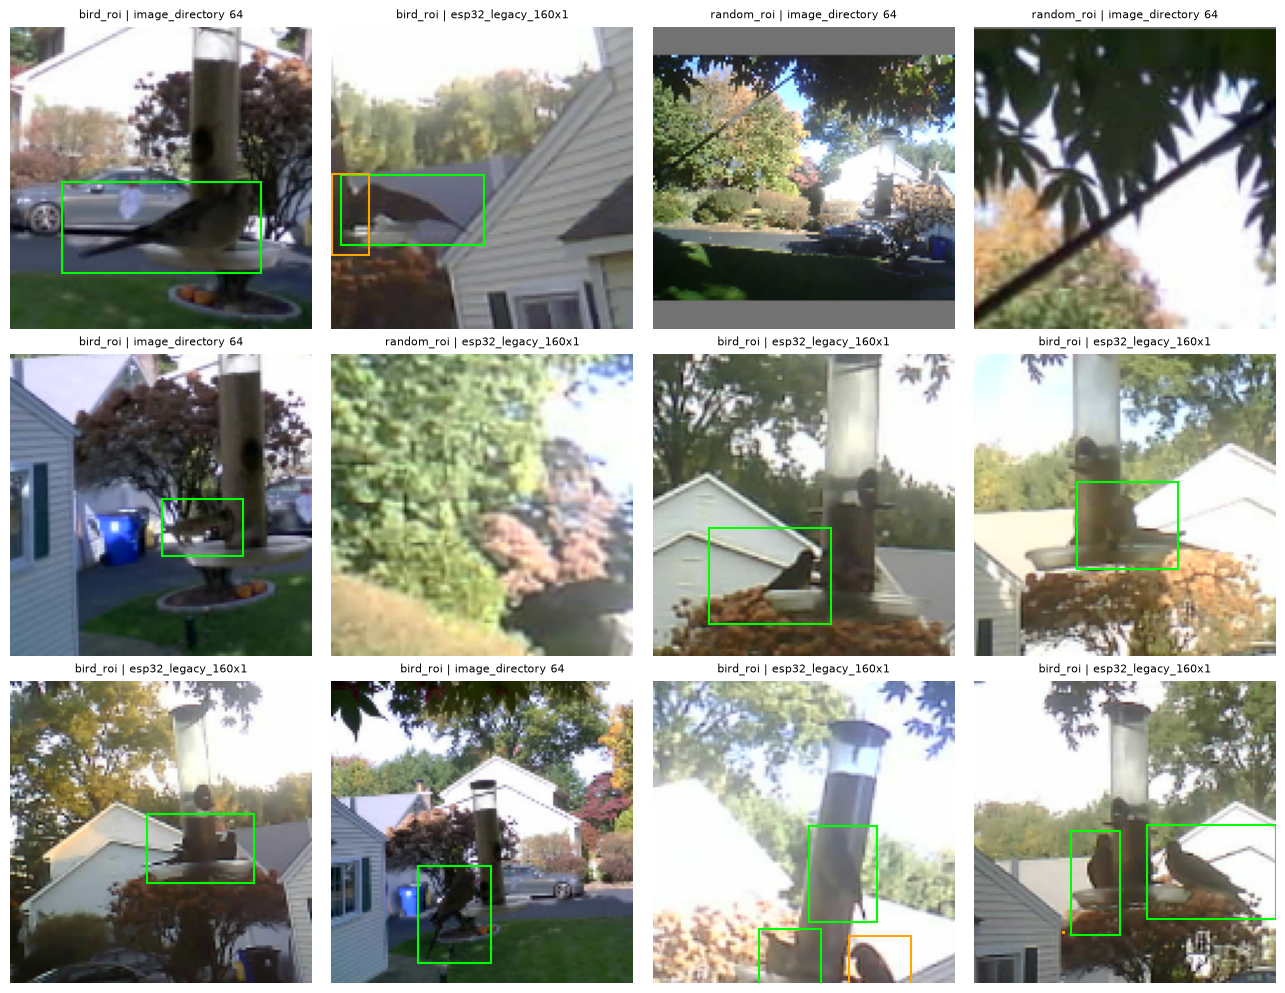

In [6]:
AUTOTUNE = tf.data.AUTOTUNE


def load_roi_tensor(path, crop_box, flip):
    image = tf.cast(tf.io.decode_jpeg(tf.io.read_file(path), channels=3), tf.float32)
    out = tf.image.crop_and_resize(image[None], crop_box[None], [0], [INPUT_SIZE, INPUT_SIZE],
                                   method="bilinear", extrapolation_value=float(PAD_VALUE))[0]
    out = tf.cond(flip, lambda: tf.image.flip_left_right(out), lambda: out)
    return tf.ensure_shape(out, (INPUT_SIZE, INPUT_SIZE, 3))


def augment(image):
    if AUGMENT_COLOR:
        image = tf.image.random_brightness(image, 20.0)
        image = tf.image.random_contrast(image, 0.8, 1.2)
        image = tf.image.random_saturation(image, 0.7, 1.3)
        # occasional greyscale: legacy captures and dusk frames
        grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(image))
        image = tf.where(tf.random.uniform([]) < 0.1, grey, image)
    return tf.clip_by_value(image, 0.0, 255.0)


def train_generator():
    rng = np.random.default_rng(SEED + 1)
    while True:
        record, roi, _, flip, positives, ignores = draw_sample(rng)
        yield (record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip,
               encode_targets(positives, ignores, ANCHORS))


signature = (
    tf.TensorSpec((), tf.string), tf.TensorSpec((4,), tf.float32), tf.TensorSpec((), tf.bool),
    tf.TensorSpec((GRID, GRID, NUM_ANCHORS, 6), tf.float32),
)
train_ds = (
    tf.data.Dataset.from_generator(train_generator, output_signature=signature)
    .map(lambda p, b, f, t: (augment(load_roi_tensor(p, b, f)), t), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(AUTOTUNE)
)


def eval_dataset(items):
    paths = [i["record"]["path"] for i in items]
    boxes = np.stack([roi_to_crop_box(i["roi"], i["record"]["width"], i["record"]["height"]) for i in items])
    targets = np.stack([encode_targets(i["positives"], i["ignores"], ANCHORS) for i in items])
    ds = tf.data.Dataset.from_tensor_slices((paths, boxes, targets))
    ds = ds.map(lambda p, b, t: (load_roi_tensor(p, b, tf.constant(False)), t), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


val_ds = eval_dataset(val_rois)

# Preview: simulated ROIs with their positive (green) and ignore (orange) targets.
preview_rng = np.random.default_rng(SEED + 99)
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax in axes.flat:
    record, roi, mode, flip, positives, ignores = draw_sample(preview_rng)
    image = load_roi_tensor(record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip).numpy()
    ax.imshow(image.astype(np.uint8))
    for boxes, colour in ((positives, "lime"), (ignores, "orange")):
        for b in boxes * INPUT_SIZE:
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=colour, lw=1.5))
    ax.set_title(f"{mode} | {record['source'][:18]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()

## 7. Model and loss

In [ ]:
def build_models():
    inputs = keras.Input((INPUT_SIZE, INPUT_SIZE, 3), name="image")
    x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_mobilenet")(inputs)
    backbone = keras.applications.MobileNetV2(
        input_shape=(INPUT_SIZE, INPUT_SIZE, 3), alpha=BACKBONE_ALPHA, include_top=False, weights=WEIGHTS)
    features = keras.Model(backbone.input, backbone.get_layer(FEATURE_LAYER).output, name="backbone")
    if WEIGHTS is None:
        # MobileNetV2's BN momentum (0.999) assumes pretrained statistics; from scratch
        # the moving averages would lag thousands of steps behind and break validation.
        for layer in features.layers:
            if isinstance(layer, keras.layers.BatchNormalization):
                layer.momentum = 0.9
    f = features(x)
    h = keras.layers.SeparableConv2D(HEAD_CHANNELS, 3, padding="same", use_bias=False, name="head_sep")(f)
    h = keras.layers.BatchNormalization(name="head_bn")(h)
    h = keras.layers.ReLU(6.0, name="head_relu")(h)
    box = keras.layers.Conv2D(NUM_ANCHORS * 4, 1, name="box")(h)
    score = keras.layers.Conv2D(NUM_ANCHORS, 1, name="score",
                                bias_initializer=keras.initializers.Constant(-4.6))(h)  # prior ~1%
    deploy = keras.Model(inputs, [box, score], name="esp32_bird_detector")
    packed = keras.layers.Concatenate(axis=-1, name="packed")([
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 4))(box),
        keras.layers.Reshape((GRID, GRID, NUM_ANCHORS, 1))(score),
    ])
    train = keras.Model(inputs, packed, name="esp32_bird_detector_train")
    return deploy, train, features


def detector_loss(y_true, y_pred):
    obj, ignore = y_true[..., 4], y_true[..., 5]
    logits = y_pred[..., 4]
    prob = tf.sigmoid(logits)
    bce = tf.nn.sigmoid_cross_entropy_with_logits(labels=obj, logits=logits)
    p_t = obj * prob + (1 - obj) * (1 - prob)
    alpha_t = obj * FOCAL_ALPHA + (1 - obj) * (1 - FOCAL_ALPHA)
    focal = alpha_t * tf.pow(1 - p_t, FOCAL_GAMMA) * bce
    score_mask = obj + (1 - obj) * (1 - ignore)
    n_pos = tf.maximum(tf.reduce_sum(obj), 1.0)
    score_loss = tf.reduce_sum(focal * score_mask) / n_pos
    t_xy = y_true[..., 0:2]
    xy_entropy = -(t_xy * tf.math.log(tf.clip_by_value(t_xy, 1e-6, 1.0))
                   + (1 - t_xy) * tf.math.log(tf.clip_by_value(1 - t_xy, 1e-6, 1.0)))
    # minus the target entropy: same gradients, but the loss reaches 0 at a perfect box
    xy = tf.reduce_sum(obj[..., None] * (tf.nn.sigmoid_cross_entropy_with_logits(labels=t_xy, logits=y_pred[..., 0:2]) - xy_entropy), -1)
    err = tf.abs(y_true[..., 2:4] - y_pred[..., 2:4])
    wh = tf.reduce_sum(tf.where(err < 1.0, 0.5 * tf.square(err), err - 0.5), -1)  # Huber, delta 1
    box_loss = tf.reduce_sum(obj * (xy + wh)) / n_pos
    return score_loss + BOX_LOSS_WEIGHT * box_loss


deploy_model, train_model, backbone_model = build_models()
deploy_model.summary()


def count_macs(model):
    macs = 0
    stack = list(model.layers)
    while stack:
        layer = stack.pop()
        if isinstance(layer, keras.Model):
            stack.extend(layer.layers)
            continue
        if not hasattr(layer, "kernel_size"):
            continue
        out_h, out_w = layer.output.shape[1], layer.output.shape[2]
        k = int(np.prod(layer.kernel_size))
        in_c = layer.input.shape[-1]
        if isinstance(layer, keras.layers.DepthwiseConv2D):
            macs += out_h * out_w * k * in_c * layer.depth_multiplier
        elif isinstance(layer, keras.layers.SeparableConv2D):
            macs += out_h * out_w * k * in_c + out_h * out_w * in_c * layer.filters
        elif isinstance(layer, keras.layers.Conv2D):
            macs += out_h * out_w * k * in_c * layer.filters
    return int(macs)


MODEL_MACS = count_macs(deploy_model)
print(f"Detector compute: {MODEL_MACS / 1e6:.1f} M MACs per inference "
      f"({deploy_model.count_params():,} parameters)")

## 8. Train: head warm-up, then full fine-tune

In [ ]:
created_utc = datetime.now(timezone.utc)
RUN_NAME = f"esp32_roi_detector_v2_{INPUT_SIZE}_{created_utc:%Y%m%dT%H%M%SZ}"
RUN_DIR = portable_path(OUTPUT_ROOT) / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
print("Run directory:", RUN_DIR)


def callbacks(stage):
    return [
        keras.callbacks.ModelCheckpoint(str(RUN_DIR / f"{stage}_best.weights.h5"), monitor="val_loss",
                                        save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOP_PATIENCE, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=max(1, EARLY_STOP_PATIENCE // 2), min_lr=1e-6, verbose=1),
        keras.callbacks.CSVLogger(str(RUN_DIR / f"{stage}_history.csv")),
        keras.callbacks.TerminateOnNaN(),
    ]


started = time.perf_counter()
histories = {}
if WEIGHTS is not None and HEAD_EPOCHS > 0:
    # A frozen *random* backbone has meaningless BatchNorm statistics, so the
    # head-only warm-up only makes sense with pretrained weights.
    backbone_model.trainable = False
    train_model.compile(optimizer=keras.optimizers.Adam(HEAD_LR), loss=detector_loss)
    histories["head"] = train_model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=HEAD_EPOCHS,
                                        validation_data=val_ds, callbacks=callbacks("head"))
    train_model.load_weights(str(RUN_DIR / "head_best.weights.h5"))

if FINE_TUNE_EPOCHS > 0:
    backbone_model.trainable = True
    train_model.compile(optimizer=keras.optimizers.Adam(FINE_TUNE_LR), loss=detector_loss)
    histories["fine_tune"] = train_model.fit(train_ds, steps_per_epoch=STEPS_PER_EPOCH, epochs=FINE_TUNE_EPOCHS,
                                             validation_data=val_ds, callbacks=callbacks("fine_tune"))
best = {stage: min(h.history["val_loss"]) for stage, h in histories.items()}
train_model.load_weights(str(RUN_DIR / f"{min(best, key=best.get)}_best.weights.h5"))
print("best val_loss per stage:", best)
TRAIN_MINUTES = (time.perf_counter() - started) / 60
print(f"training time {TRAIN_MINUTES:.1f} min")

fig, ax = plt.subplots(figsize=(7, 4))
offset = 0
for stage, history in histories.items():
    n = len(history.history["loss"])
    ax.plot(range(offset, offset + n), history.history["loss"], label=f"{stage} train")
    ax.plot(range(offset, offset + n), history.history["val_loss"], "--", label=f"{stage} val")
    offset += n
ax.set(xlabel="epoch", ylabel="loss", yscale="log")
ax.legend()
plt.savefig(RUN_DIR / "training_loss.png", dpi=140, bbox_inches="tight")

## 9. Export float32 and full-integer TFLite

Input is **uint8 RGB** with the `[0, 255] → [−1, 1]` scaling inside the graph, so the firmware copies resampled bytes straight into the input tensor. Outputs are int8; dequantize with each tensor's `(scale, zero_point)`.

In [ ]:
FLOAT_PATH = RUN_DIR / "esp32_detector_float32.tflite"
INT8_PATH = RUN_DIR / "esp32_detector_int8.tflite"
deploy_model.save(RUN_DIR / "esp32_detector.keras")
FLOAT_PATH.write_bytes(tf.lite.TFLiteConverter.from_keras_model(deploy_model).convert())


def representative_dataset():
    rng = np.random.default_rng(SEED + 21)
    for _ in range(REPRESENTATIVE_SAMPLES):
        record, roi, _, flip, _, _ = draw_sample(rng)
        image = load_roi_tensor(record["path"], roi_to_crop_box(roi, record["width"], record["height"]), flip)
        yield [image[None].numpy().astype(np.float32)]


converter = tf.lite.TFLiteConverter.from_keras_model(deploy_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.int8
INT8_PATH.write_bytes(converter.convert())

for path in (FLOAT_PATH, INT8_PATH):
    print(f"{path.name}: {path.stat().st_size / 1024:.1f} KiB")

# Ops the firmware's MicroMutableOpResolver must register.
probe = tf.lite.Interpreter(  # no XNNPACK, so the op list is the real graph
    model_path=str(INT8_PATH),
    experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
probe.allocate_tensors()
TFLITE_OPS = sorted({op["op_name"] for op in probe._get_ops_details()})
RESOLVER_NAMES = {
    "CONV_2D": "AddConv2D", "DEPTHWISE_CONV_2D": "AddDepthwiseConv2D", "ADD": "AddAdd", "PAD": "AddPad",
    "QUANTIZE": "AddQuantize", "DEQUANTIZE": "AddDequantize", "MUL": "AddMul", "RELU6": "AddRelu6",
    "RESHAPE": "AddReshape", "CONCATENATION": "AddConcatenation", "SUB": "AddSub", "MEAN": "AddMean",
}
print("TFLite ops:", TFLITE_OPS)
print("Resolver:  ", " ".join(f"resolver.{RESOLVER_NAMES.get(op, '<unmapped ' + op + '>')}();" for op in TFLITE_OPS))
print(f"MicroMutableOpResolver<{len(TFLITE_OPS)}> resolver;")

## 10. Decode, run, and evaluate on fixed validation ROIs

The threshold is tuned on motion ROIs only (`THRESHOLD_MODES`), maximising crop recall subject to `MAX_FALSE_TRIGGER_RATE`: a false trigger just costs one crop that the Pi's isBird rejects, a miss loses the bird. Whole-frame ROIs are reported but not tuned on; the firmware uses them only when no motion box is available.

The metric that matters downstream is **crop recall**: did the best-scoring detection's Pi crop (box + `PI_CROP_CONTEXT`) contain at least `CROP_COVERAGE_MIN` of a real bird? IoU recall is reported too. On negative ROIs (no bird, no ignore area) any detection above threshold is a false trigger that would send a crop to the Pi.

The first cell below only defines decode/inference helpers; section 13 reuses them without retraining.

In [7]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


GY, GX = np.meshgrid(np.arange(GRID), np.arange(GRID), indexing="ij")


def decode(box_raw, score_raw, threshold=CANDIDATE_SCORE_THRESHOLD):
    """Raw float outputs (G, G, A*4) and (G, G, A) -> boxes (N, 4) normalized xyxy, scores (N,)."""
    b = box_raw.reshape(GRID, GRID, NUM_ANCHORS, 4)
    s = sigmoid(score_raw.reshape(GRID, GRID, NUM_ANCHORS))
    cx = (sigmoid(b[..., 0]) * 3 - 1 + GX[..., None]) / GRID
    cy = (sigmoid(b[..., 1]) * 3 - 1 + GY[..., None]) / GRID
    w = ANCHORS[:, 0] * np.exp(np.clip(b[..., 2], -4, 4))
    h = ANCHORS[:, 1] * np.exp(np.clip(b[..., 3], -4, 4))
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1).reshape(-1, 4)
    scores = s.reshape(-1)
    keep = scores >= threshold
    boxes, scores = np.clip(boxes[keep], 0, 1), scores[keep]
    order = np.argsort(-scores)
    chosen = []
    while order.size and len(chosen) < MAX_DETECTIONS:
        i = order[0]
        chosen.append(i)
        order = order[1:][iou_one_to_many(boxes[i], boxes[order[1:]]) < NMS_IOU]
    return boxes[chosen], scores[chosen]


def iou_one_to_many(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0)
    ix = np.clip(np.minimum(box[2], boxes[:, 2]) - np.maximum(box[0], boxes[:, 0]), 0, None)
    iy = np.clip(np.minimum(box[3], boxes[:, 3]) - np.maximum(box[1], boxes[:, 1]), 0, None)
    inter = ix * iy
    area = lambda bb: (bb[..., 2] - bb[..., 0]) * (bb[..., 3] - bb[..., 1])
    return inter / np.maximum(area(box) + area(boxes) - inter, 1e-9)


def crop_coverage(det_norm, gt_norm):
    """Share of each GT box inside the context-expanded crop of det (ROI-normalized coords)."""
    w, h = det_norm[2] - det_norm[0], det_norm[3] - det_norm[1]
    crop = np.array([det_norm[0] - PI_CROP_CONTEXT * w, det_norm[1] - PI_CROP_CONTEXT * h,
                     det_norm[2] + PI_CROP_CONTEXT * w, det_norm[3] + PI_CROP_CONTEXT * h])
    ix = np.clip(np.minimum(crop[2], gt_norm[:, 2]) - np.maximum(crop[0], gt_norm[:, 0]), 0, None)
    iy = np.clip(np.minimum(crop[3], gt_norm[:, 3]) - np.maximum(crop[1], gt_norm[:, 1]), 0, None)
    return ix * iy / np.maximum((gt_norm[:, 2] - gt_norm[:, 0]) * (gt_norm[:, 3] - gt_norm[:, 1]), 1e-9)


def limit(items):
    if TFLITE_EVAL_LIMIT is None or len(items) <= TFLITE_EVAL_LIMIT:
        return items
    rng = np.random.default_rng(SEED + 5)
    return [items[i] for i in sorted(rng.choice(len(items), TFLITE_EVAL_LIMIT, replace=False))]


def roi_image(item):
    r = item["record"]
    return load_roi_tensor(r["path"], roi_to_crop_box(item["roi"], r["width"], r["height"]), tf.constant(False)).numpy()


def run_tflite(model_path, items):
    interpreter = tf.lite.Interpreter(model_path=str(model_path), num_threads=4)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    outs = {d["name"]: d for d in interpreter.get_output_details()}
    # Identify box/score outputs by channel count, never by order.
    box_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS * 4)
    score_d = next(d for d in outs.values() if d["shape"][-1] == NUM_ANCHORS)

    def deq(detail):
        raw = interpreter.get_tensor(detail["index"])[0]
        scale, zero = detail["quantization"]
        return raw.astype(np.float32) if scale == 0 else (raw.astype(np.float32) - zero) * scale

    results, seconds = [], 0.0
    for item in items:
        x = roi_image(item)[None]
        if inp["dtype"] == np.uint8:
            scale, zero = inp["quantization"]
            x = np.clip(np.rint(x / scale + zero), 0, 255).astype(np.uint8)
        interpreter.set_tensor(inp["index"], x.astype(inp["dtype"]))
        t0 = time.perf_counter()
        interpreter.invoke()
        seconds += time.perf_counter() - t0
        results.append((deq(box_d), deq(score_d)))
    details = {"input": [list(map(float, inp["quantization"])), np.dtype(inp["dtype"]).name],
               "box": [list(map(float, box_d["quantization"])), np.dtype(box_d["dtype"]).name, box_d["name"]],
               "score": [list(map(float, score_d["quantization"])), np.dtype(score_d["dtype"]).name, score_d["name"]],
               "host_ms_per_roi": 1000 * seconds / max(1, len(items))}
    return results, details


def roi_outcomes(items, raw_outputs):
    """Per ROI: best detection score for crop recall / IoU recall, and max score for false triggers."""
    rows = []
    for item, (box_raw, score_raw) in zip(items, raw_outputs):
        boxes, scores = decode(box_raw, score_raw)
        gt = item["positives"]
        row = {"mode": item["mode"], "source": item["record"]["source"], "has_bird": len(gt) > 0,
               "negative": len(gt) == 0 and len(item["ignores"]) == 0,
               "max_score": float(scores.max()) if len(scores) else 0.0,
               "crop_hit_score": 0.0, "iou_hit_score": 0.0}
        if len(gt) and len(boxes):
            # The firmware sends one crop: the top detection. Score it as such.
            top = boxes[0]
            if (crop_coverage(top, gt) >= CROP_COVERAGE_MIN).any():
                row["crop_hit_score"] = float(scores[0])
            ious = np.array([iou_one_to_many(b, gt).max() for b in boxes])
            hits = scores[ious >= IOU_MATCH]
            row["iou_hit_score"] = float(hits.max()) if len(hits) else 0.0
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_at(outcomes, threshold):
    birds, negatives = outcomes[outcomes["has_bird"]], outcomes[outcomes["negative"]]
    return {
        "threshold": float(threshold),
        "bird_rois": len(birds), "negative_rois": len(negatives),
        "crop_recall": float((birds["crop_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "iou_recall": float((birds["iou_hit_score"] >= threshold).mean()) if len(birds) else np.nan,
        "false_trigger_rate": float((negatives["max_score"] >= threshold).mean()) if len(negatives) else np.nan,
    }

In [ ]:
val_eval = limit(val_rois)
val_raw_float, float_details = run_tflite(FLOAT_PATH, val_eval)
val_raw_int8, int8_details = run_tflite(INT8_PATH, val_eval)
val_float = roi_outcomes(val_eval, val_raw_float)
val_int8 = roi_outcomes(val_eval, val_raw_int8)
print("int8 tensors:", int8_details)
drift = np.mean([np.abs(sigmoid(a[1]) - sigmoid(b[1])).max() for a, b in zip(val_raw_float, val_raw_int8)])
print(f"mean per-ROI max |score_float - score_int8| = {drift:.4f}")

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
tune_int8 = val_int8[val_int8["mode"].isin(THRESHOLD_MODES)]
sweep = pd.DataFrame([metrics_at(tune_int8, t) for t in thresholds])
sweep_float = pd.DataFrame([metrics_at(val_float[val_float["mode"].isin(THRESHOLD_MODES)], t) for t in thresholds])
sweep.to_csv(RUN_DIR / "validation_threshold_sweep_int8.csv", index=False)
ok = sweep[sweep["false_trigger_rate"] <= MAX_FALSE_TRIGGER_RATE]
if ok.empty:
    print(f"warning: no threshold keeps false triggers <= {MAX_FALSE_TRIGGER_RATE}; using the highest swept threshold")
    DEPLOY_THRESHOLD = float(thresholds[-1])
else:
    # best recall; among ties the higher threshold (fewer wasted crops)
    DEPLOY_THRESHOLD = float(ok.sort_values(["crop_recall", "threshold"], ascending=[False, False]).iloc[0]["threshold"])
print("Deployment score threshold (int8, validation):", DEPLOY_THRESHOLD)
display(pd.DataFrame([metrics_at(tune_int8, DEPLOY_THRESHOLD)]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold"], sweep["crop_recall"], label="crop recall (int8)")
ax.plot(sweep["threshold"], sweep["iou_recall"], label="IoU recall (int8)")
ax.plot(sweep["threshold"], sweep["false_trigger_rate"], label="false trigger rate (int8)")
ax.plot(sweep_float["threshold"], sweep_float["crop_recall"], ":", label="crop recall (float)")
ax.axvline(DEPLOY_THRESHOLD, color="k", lw=1)
ax.set(xlabel="score threshold", ylim=(0, 1.02))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.savefig(RUN_DIR / "validation_sweep.png", dpi=140, bbox_inches="tight")

## 11. Test once, with per-mode and per-source breakdown

In [ ]:
test_eval = limit(test_rois)
test_raw_int8, _ = run_tflite(INT8_PATH, test_eval)
test_int8 = roi_outcomes(test_eval, test_raw_int8)

rows = []
for split, outcomes in (("validation", val_int8), ("test", test_int8)):
    rows.append({"split": split, "slice": "motion ROIs (tuned)",
                 **metrics_at(outcomes[outcomes["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD)})
    rows.append({"split": split, "slice": "all", **metrics_at(outcomes, DEPLOY_THRESHOLD)})
    for (mode, source), part in outcomes.groupby(["mode", "source"]):
        rows.append({"split": split, "slice": f"{mode} / {source}", **metrics_at(part, DEPLOY_THRESHOLD)})
results = pd.DataFrame(rows)
results.to_csv(RUN_DIR / "results_int8.csv", index=False)
display(results)

# Visual check: test ROIs with ground truth (green), top detection (red), and its Pi crop region (dashed).
fig, axes = plt.subplots(3, 4, figsize=(13, 10))
pick = np.random.default_rng(SEED + 3).choice(len(test_eval), size=min(12, len(test_eval)), replace=False)
for ax, i in zip(axes.flat, pick):
    item = test_eval[i]
    ax.imshow(roi_image(item).astype(np.uint8))
    for b in item["positives"] * INPUT_SIZE:
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="lime", lw=1.5))
    boxes, scores = decode(*test_raw_int8[i])
    if len(scores) and scores[0] >= DEPLOY_THRESHOLD:
        b = boxes[0]
        w, h = b[2] - b[0], b[3] - b[1]
        c = np.array([b[0] - PI_CROP_CONTEXT * w, b[1] - PI_CROP_CONTEXT * h, b[2] + PI_CROP_CONTEXT * w, b[3] + PI_CROP_CONTEXT * h]) * INPUT_SIZE
        b = b * INPUT_SIZE
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color="red", lw=1.5))
        ax.add_patch(plt.Rectangle((c[0], c[1]), c[2] - c[0], c[3] - c[1], fill=False, color="red", lw=1, ls="--"))
        ax.set_title(f"{item['mode']} score {scores[0]:.2f}", fontsize=8)
    else:
        ax.set_title(f"{item['mode']} (no trigger)", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RUN_DIR / "test_examples.png", dpi=140, bbox_inches="tight")

# End-to-end reference: frame -> ROI -> detection -> what the Pi would receive.
demo = next((item for item in test_eval if len(item["positives"])), test_eval[0])
boxes, scores = decode(*test_raw_int8[test_eval.index(demo)])
if len(scores):
    full = decode_rgb(demo["record"]["path"])
    pi_crop, pi_meta = make_pi_crop(full, roi_box_to_frame(boxes[0], demo["roi"]))
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(full)
    l, t, r, b = demo["roi"]
    axes[0].add_patch(plt.Rectangle((l, t), r - l, b - t, fill=False, color="yellow"))
    cl, ct, cr, cb = pi_meta["crop_px"]
    axes[0].add_patch(plt.Rectangle((cl, ct), cr - cl, cb - ct, fill=False, color="red"))
    axes[0].set_title("frame: ROI (yellow), Pi crop (red)")
    axes[1].imshow(pi_crop)
    axes[1].set_title(f"sent to Pi: {PI_CROP_SIZE}x{PI_CROP_SIZE}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()

## 12. Firmware artifacts and contract

- `esp32_detector_model.h` — the int8 model as a 16-byte-aligned C array (put it in `include/`).
- `esp32_detector_contract.h` — every constant the firmware needs: geometry, anchors, quantization, threshold, op count.
- `esp32_detector_contract.json` — the same contract for the Pi / isBird notebook.

Measure `interpreter.arena_used_bytes()` on the board and set the tensor arena from it; allocate the arena in PSRAM.

In [ ]:
int8_bytes = INT8_PATH.read_bytes()
box_q, score_q, in_q = int8_details["box"][0], int8_details["score"][0], int8_details["input"][0]

contract = {
    "schema_version": 1,
    "run_name": RUN_NAME,
    "created_utc": created_utc.isoformat(),
    "model_file": INT8_PATH.name,
    "model_sha256": sha256_file(INT8_PATH),
    "model_bytes": len(int8_bytes),
    "model_macs": MODEL_MACS,
    "tflite_ops": TFLITE_OPS,
    "input": {
        "shape": [1, INPUT_SIZE, INPUT_SIZE, 3], "dtype": "uint8", "color_order": "RGB",
        "quantization": in_q, "numeric_scaling": "[0,255] -> [-1,1] inside the model",
    },
    "outputs": {
        "box": {"shape": [1, GRID, GRID, NUM_ANCHORS * 4], "dtype": "int8", "quantization": box_q,
                "layout": "[gy][gx][anchor][tx,ty,tw,th]", "tensor_name": int8_details["box"][2]},
        "score": {"shape": [1, GRID, GRID, NUM_ANCHORS], "dtype": "int8", "quantization": score_q,
                  "layout": "[gy][gx][anchor] logit", "tensor_name": int8_details["score"][2]},
        "identify_outputs_by": "last dimension (A*4 = box, A = score), not by index",
    },
    "anchors_normalized_wh": ANCHORS,
    "decode": {
        "center_x": "(sigmoid(tx) * 3 - 1 + gx) / G", "center_y": "(sigmoid(ty) * 3 - 1 + gy) / G",
        "width": "anchor_w * exp(clamp(tw, -4, 4))", "height": "anchor_h * exp(clamp(th, -4, 4))",
        "score": "sigmoid(logit)", "coordinates": "normalized to the square ROI",
        "candidate_score_threshold": CANDIDATE_SCORE_THRESHOLD, "nms_iou": NMS_IOU,
        "max_detections": MAX_DETECTIONS, "deployment_score_threshold": DEPLOY_THRESHOLD,
        "deployment_logit_threshold": float(np.log(DEPLOY_THRESHOLD / (1 - DEPLOY_THRESHOLD))),
    },
    "roi": {
        "function": "square_roi", "expand": ROI_EXPAND, "min_side_fraction_of_min_frame_dim": ROI_MIN_SIDE_FRACTION,
        "max_side": "max(frame_w, frame_h)", "rounding": "side, x0, y0 rounded half-away from zero",
        "placement": "slide inside frame if side fits that axis, else centre ((frame - side) // 2)",
    },
    "resample": {
        "method": "bilinear, pixel-centre aligned",
        "formula": "src = start + (dst + 0.5) * extent / out - 0.5",
        "outside_frame": "PAD_VALUE for samples outside [0, W-1] x [0, H-1]", "pad_value": PAD_VALUE,
    },
    "pi_crop": {
        "detection": "top-scoring box only", "context_per_edge": PI_CROP_CONTEXT,
        "rounding": "floor(left, top), ceil(right, bottom), clipped to the frame",
        "output": [PI_CROP_SIZE, PI_CROP_SIZE, 3], "letterbox": "aspect-preserving, centred, (out - new) // 2",
        "pad_value": PAD_VALUE, "resample": "same bilinear formula",
    },
    "threshold_policy": {"modes": list(THRESHOLD_MODES), "max_false_trigger_rate": MAX_FALSE_TRIGGER_RATE},
    "validation_int8": metrics_at(val_int8[val_int8["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD),
    "test_int8": metrics_at(test_int8[test_int8["mode"].isin(THRESHOLD_MODES)], DEPLOY_THRESHOLD),
    "training": {"combined_csv": str(COMBINED_CSV_PATH), "combined_csv_sha256": sha256_file(COMBINED_CSV_PATH),
                 "sample_mix": SAMPLE_MIX, "minutes": TRAIN_MINUTES, "seed": SEED, "quick_run": QUICK_RUN},
}
(RUN_DIR / "esp32_detector_contract.json").write_text(json.dumps(json_safe(contract), indent=2), encoding="utf-8")
(RUN_DIR / "anchors.json").write_text(json.dumps(ANCHORS.tolist()), encoding="utf-8")

hex_lines = [", ".join(f"0x{b:02x}" for b in int8_bytes[i:i + 16]) for i in range(0, len(int8_bytes), 16)]
(RUN_DIR / "esp32_detector_model.h").write_text(
    "// Generated by train_esp32_roi_detector.ipynb - do not edit.\n"
    f"// {RUN_NAME}  sha256 {contract['model_sha256']}\n"
    "#pragma once\n#include <stddef.h>\n#include <stdint.h>\n\n"
    "alignas(16) const uint8_t kBirdDetectorModel[] = {\n  " + ",\n  ".join(hex_lines) + "\n};\n"
    f"const size_t kBirdDetectorModelLen = {len(int8_bytes)};\n", encoding="utf-8")

anchor_rows = ",\n  ".join(f"{{{a[0]:.6f}f, {a[1]:.6f}f}}" for a in ANCHORS)
(RUN_DIR / "esp32_detector_contract.h").write_text(f"""// Generated by train_esp32_roi_detector.ipynb - do not edit.
// {RUN_NAME}
#pragma once

constexpr int kDetInputSize = {INPUT_SIZE};
constexpr int kDetGrid = {GRID};
constexpr int kDetAnchors = {NUM_ANCHORS};
constexpr float kDetAnchorsWH[kDetAnchors][2] = {{
  {anchor_rows}
}};
constexpr float kDetBoxScale = {box_q[0]:.9g}f;
constexpr int kDetBoxZeroPoint = {int(box_q[1])};
constexpr float kDetScoreScale = {score_q[0]:.9g}f;
constexpr int kDetScoreZeroPoint = {int(score_q[1])};
constexpr float kDetScoreThreshold = {DEPLOY_THRESHOLD:.4f}f;
constexpr float kDetCandidateThreshold = {CANDIDATE_SCORE_THRESHOLD:.4f}f;
constexpr float kDetNmsIou = {NMS_IOU:.3f}f;
constexpr int kDetMaxDetections = {MAX_DETECTIONS};
constexpr int kDetOpCount = {len(TFLITE_OPS)};  // MicroMutableOpResolver<kDetOpCount>

constexpr float kRoiExpand = {ROI_EXPAND:.4f}f;
constexpr float kRoiMinSideFraction = {ROI_MIN_SIDE_FRACTION:.4f}f;
constexpr int kPadValue = {PAD_VALUE};

constexpr float kPiCropContext = {PI_CROP_CONTEXT:.4f}f;
constexpr int kPiCropSize = {PI_CROP_SIZE};
""", encoding="utf-8")

print("Wrote", RUN_DIR)
for path in sorted(RUN_DIR.iterdir()):
    print(f"  {path.name:42s} {path.stat().st_size / 1024:9.1f} KiB")

## 13. Label review: possible unlabelled birds and missed birds

Runs the int8 detector over the fixed evaluation ROIs plus an overlapping tile grid (so a small bird anywhere in an "empty" frame is seen at a usable scale) for every split, and flags two kinds of image:

- **`possible_unlabelled_bird`**: a detection at or above the review threshold that does not overlap any labelled or ignore box. Either a false trigger or a bird that has no box.
- **`missed_bird`**: a labelled bird that the top detection's Pi crop does not cover. Either a detector miss or a box that is wrong (loose, misplaced, not a bird).

Outputs in `<run>/label_review/`:

- `review_subset.csv`: the flagged images' rows from `combined_annotations.csv`, unchanged, strongest flags first. Open it in `scripts/bbox_viewer.py`, which edits it in place.
- `review_queue.csv`: why each image was flagged, with the detection box in frame pixels (the viewer hides machine boxes, so look here or at the contact sheet).
- `possible_unlabelled_birds.png`: contact sheet of the strongest flags.

Then set `APPLY_REVIEW = True` in the last cell to merge your edits back into the master CSV. A timestamped backup is written first.

**Train-split flags are an underestimate.** The model was trained to call any unlabelled bird in a training frame "background", so it scores those lower than it would on unseen frames. Validation and test flags are unbiased; to audit train properly, review, merge, retrain, and review again.

**Without retraining:** run sections 1–6, the helper cell at the start of section 10, then this section with `REVIEW_RUN_DIR` set to an earlier run. The split and ROIs are deterministic, so they match that run as long as the CSV and config are unchanged.

reviewing esp32_detector_int8.tflite from esp32_roi_detector_v2_128_20261102T225645Z at score >= 0.30


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


train: 87,819 ROIs scored in 1974s
validation: 18,906 ROIs scored in 458s
test: 18,634 ROIs scored in 422s


,images,unlabelled_flags,unlabelled_score>=0.5,unlabelled_score>=0.8,missed_bird_flags
test,1282,481,163,7,350
train,5953,1480,475,53,1151
validation,1276,393,104,12,470


unlabelled_flags
source                       mode                         
esp32_legacy_160x120 160x120 random_roi                  6
                             review_tile               379
esp32_legacy_160x120 640x480 bird_roi                   29
                             random_roi                 77
                             review_tile               565
                             whole_frame               310
image_directory 640x480      bird_roi                   80
                             random_roi                 87
                             review_tile               606
                             whole_frame               215

High-scoring (>= 0.8) unlabelled flags are the ones most likely to be real birds without a box.
3,682 images -> /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z/label_review/review_subset.csv
open with:  python scripts\bbox_viewer.py "/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/esp32_roi_detector_v2_128_20261102T225645Z/label_review/review_subset.csv"


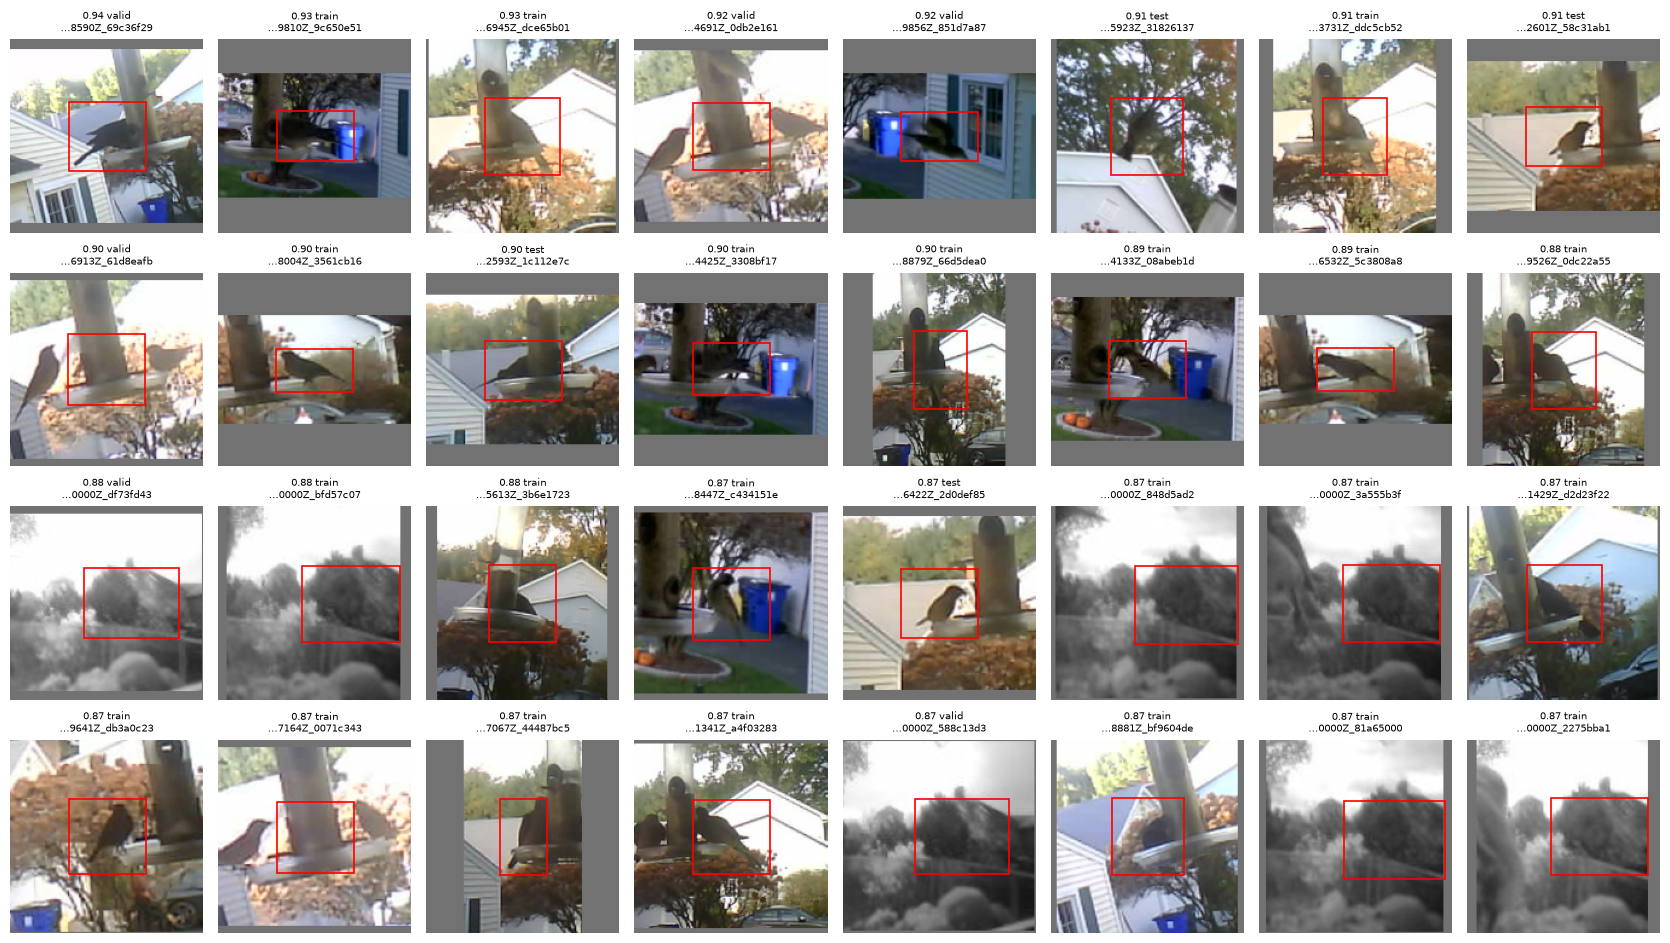

In [9]:
REVIEW_RUN_DIR = r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Multi_Object_Detector\runs\esp32_roi_detector_v2_128_20261102T225645Z"       # e.g. r"C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Models\Multi_Object_Detector\runs\esp32_roi_detector_v2_128_20261102T225645Z"
REVIEW_SPLITS = ("train", "validation", "test")
REVIEW_MIN_SCORE = 0.3      # review candidates, not deployment: lower than the deploy threshold on purpose (None = use it)
REVIEW_TILE_FRACTION = 0.5  # also score overlapping square tiles (side = this x min(frame w, h)); None disables
REVIEW_TILE_OVERLAP = 0.25
REVIEW_MAX_LABEL_OVERLAP = 0.1  # "unlabelled" if less than this share of the detection overlaps any labelled box
CONTACT_SHEET_COUNT = 32

import shutil

if REVIEW_RUN_DIR:
    review_run = portable_path(REVIEW_RUN_DIR)
    review_contract = json.loads((review_run / "esp32_detector_contract.json").read_text(encoding="utf-8"))
    review_model = review_run / "esp32_detector_int8.tflite"
    ANCHORS = np.asarray(review_contract["anchors_normalized_wh"], np.float32)  # decode() reads this global
    review_threshold = float(review_contract["decode"]["deployment_score_threshold"])
else:
    review_run, review_model, review_threshold = RUN_DIR, INT8_PATH, DEPLOY_THRESHOLD
if REVIEW_MIN_SCORE is not None:
    review_threshold = float(REVIEW_MIN_SCORE)
REVIEW_DIR = review_run / "label_review"
REVIEW_DIR.mkdir(exist_ok=True)
print(f"reviewing {review_model.name} from {review_run.name} at score >= {review_threshold:.2f}")


def overlap_share(box, others):
    """Largest share of `box` covered by any single box in `others` (normalized xyxy)."""
    if len(others) == 0:
        return 0.0
    ix = np.clip(np.minimum(box[2], others[:, 2]) - np.maximum(box[0], others[:, 0]), 0, None)
    iy = np.clip(np.minimum(box[3], others[:, 3]) - np.maximum(box[1], others[:, 1]), 0, None)
    return float((ix * iy).max() / max((box[2] - box[0]) * (box[3] - box[1]), 1e-9))


def review_rois(subset, seed):
    """Fixed training-style ROIs plus a tile grid, so small birds anywhere in a frame are seen at a usable scale."""
    items = fixed_roi_set(subset, seed)
    if not REVIEW_TILE_FRACTION:
        return items
    for record in subset:
        W, H = record["width"], record["height"]
        side = max(1, int(round(REVIEW_TILE_FRACTION * min(W, H))))
        step = max(1, int(side * (1 - REVIEW_TILE_OVERLAP)))
        xs = sorted(set(list(range(0, max(W - side, 0) + 1, step)) + [max(W - side, 0)]))
        ys = sorted(set(list(range(0, max(H - side, 0) + 1, step)) + [max(H - side, 0)]))
        for y in ys:
            for x in xs:
                roi = (x, y, x + side, y + side)
                positives, ignores = roi_targets_from_record(record, roi)
                items.append({"record": record, "roi": roi, "mode": "review_tile",
                              "positives": positives, "ignores": ignores})
    return items


split_records = {"train": train_records, "validation": val_records, "test": test_records}
split_seeds = {"train": SEED + 17, "validation": SEED + 11, "test": SEED + 13}
flags = []
for split in REVIEW_SPLITS:
    items = review_rois(split_records[split], split_seeds[split])
    t0 = time.perf_counter()
    raw, _ = run_tflite(review_model, items)
    print(f"{split}: {len(items):,} ROIs scored in {time.perf_counter() - t0:.0f}s")
    for item, (box_raw, score_raw) in zip(items, raw):
        boxes, scores = decode(box_raw, score_raw)
        record, roi = item["record"], item["roi"]
        labelled = np.concatenate([item["positives"], item["ignores"]]).reshape(-1, 4)
        base = {"sample_id": record["sample_id"], "split": split, "source": record["source"], "mode": item["mode"],
                "image_path": record["path"], "labelled_boxes_in_image": len(record["boxes"]) + len(record["ignore"]),
                "roi_px": list(roi)}
        for box, score in zip(boxes, scores):
            if score < review_threshold:
                break
            if overlap_share(box, labelled) < REVIEW_MAX_LABEL_OVERLAP:
                det_px = roi_box_to_frame(box, roi)
                flags.append(base | {"kind": "possible_unlabelled_bird", "score": float(score),
                                     "det_xmin": det_px[0], "det_ymin": det_px[1], "det_xmax": det_px[2], "det_ymax": det_px[3]})
                break  # one flag per ROI is enough to send the image for review
        gt = item["positives"]
        if len(gt) and item["mode"] != "review_tile":
            hit = bool(len(boxes)) and scores[0] >= review_threshold and bool(
                (crop_coverage(boxes[0], gt) >= CROP_COVERAGE_MIN).any())
            if not hit:
                det_px = roi_box_to_frame(boxes[0], roi) if len(boxes) else [np.nan] * 4
                flags.append(base | {"kind": "missed_bird", "score": float(scores[0]) if len(scores) else 0.0,
                                     "det_xmin": det_px[0], "det_ymin": det_px[1], "det_xmax": det_px[2], "det_ymax": det_px[3]})

queue = pd.DataFrame(flags)
if queue.empty:
    print("nothing flagged")
else:
    # One row per image and kind, keeping its strongest ROI; unlabelled-looking detections first.
    queue = queue.sort_values("score", ascending=False).drop_duplicates(["sample_id", "kind"])
    queue["_rank"] = queue["kind"].map({"possible_unlabelled_bird": 0, "missed_bird": 1})
    queue = queue.sort_values(["_rank", "score"], ascending=[True, False]).drop(columns="_rank").reset_index(drop=True)
    queue.to_csv(REVIEW_DIR / "review_queue.csv", index=False)

    unl = queue[queue["kind"] == "possible_unlabelled_bird"]
    summary = pd.DataFrame({
        "images": pd.Series({s: len(split_records[s]) for s in REVIEW_SPLITS}),
        "unlabelled_flags": unl.groupby("split")["sample_id"].nunique(),
        "unlabelled_score>=0.5": unl[unl["score"] >= 0.5].groupby("split")["sample_id"].nunique(),
        "unlabelled_score>=0.8": unl[unl["score"] >= 0.8].groupby("split")["sample_id"].nunique(),
        "missed_bird_flags": queue[queue["kind"] == "missed_bird"].groupby("split")["sample_id"].nunique(),
    }).fillna(0).astype(int)
    display(summary)
    display(unl.groupby(["source", "mode"])["sample_id"].nunique().rename("unlabelled_flags").to_frame())
    print("High-scoring (>= 0.8) unlabelled flags are the ones most likely to be real birds without a box.")

    # The flagged images' original rows, in review order, for bbox_viewer.py.
    master = pd.read_csv(COMBINED_CSV_PATH, low_memory=False)
    order = {sid: i for i, sid in enumerate(queue["sample_id"].drop_duplicates())}
    subset = master[master["sample_id"].isin(order)].copy()
    subset["_order"] = subset["sample_id"].map(order)
    subset = subset.sort_values(["_order", "box_id"] if "box_id" in subset else ["_order"]).drop(columns="_order")
    subset.to_csv(REVIEW_DIR / "review_subset.csv", index=False)
    print(f"{subset['sample_id'].nunique():,} images -> {REVIEW_DIR / 'review_subset.csv'}")
    print(f'open with:  python scripts\\bbox_viewer.py "{REVIEW_DIR / "review_subset.csv"}"')

    # Contact sheet of the strongest unlabelled-looking detections, cropped from the full frame.
    top = unl.head(CONTACT_SHEET_COUNT)
    if len(top):
        cols = 8
        fig, axes = plt.subplots(int(math.ceil(len(top) / cols)), cols,
                                 figsize=(2.1 * cols, 2.4 * math.ceil(len(top) / cols)), squeeze=False)
        for ax in axes.flat:
            ax.axis("off")
        for ax, row in zip(axes.flat, top.itertuples(index=False)):
            det = (row.det_xmin, row.det_ymin, row.det_xmax, row.det_ymax)
            crop, meta = make_pi_crop(decode_rgb(row.image_path), det, out_size=160, context=0.75)
            (left, top_px), (ox, oy), k = meta["crop_px"][:2], meta["offset"], meta["scale"]
            ax.imshow(crop)
            ax.add_patch(plt.Rectangle((ox + (det[0] - left) * k, oy + (det[1] - top_px) * k),
                                       (det[2] - det[0]) * k, (det[3] - det[1]) * k, fill=False, color="red", lw=1.2))
            ax.set_title(f"{row.score:.2f} {row.split[:5]}\n…{row.sample_id[-14:]}", fontsize=7)
        plt.tight_layout()
        plt.savefig(REVIEW_DIR / "possible_unlabelled_birds.png", dpi=130, bbox_inches="tight")

In [ ]:
# After fixing review_subset.csv in bbox_viewer.py, merge the edits back into the master CSV.
APPLY_REVIEW = False


def apply_review(review_csv, master_csv):
    review_csv, master_csv = Path(review_csv), Path(master_csv)
    master = pd.read_csv(master_csv, low_memory=False)
    reviewed = pd.read_csv(review_csv, low_memory=False)
    ids = set(reviewed["sample_id"])
    unknown = ids - set(master["sample_id"])
    if unknown:
        raise ValueError(f"{len(unknown)} reviewed sample_ids are not in the master CSV, e.g. {sorted(unknown)[:3]}")
    backup = master_csv.with_name(f"{master_csv.stem}_backup_{datetime.now():%Y%m%dT%H%M%S}.csv")
    shutil.copy2(master_csv, backup)
    position = master.drop_duplicates("sample_id").reset_index().set_index("sample_id")["index"]
    columns = list(master.columns) + [c for c in reviewed.columns if c not in master.columns]
    merged = pd.concat([master[~master["sample_id"].isin(ids)], reviewed], ignore_index=True).reindex(columns=columns)
    merged["_pos"] = merged["sample_id"].map(position)
    merged = merged.sort_values(["_pos", "box_id"] if "box_id" in merged else ["_pos"], kind="stable").drop(columns="_pos")
    merged.to_csv(master_csv, index=False)
    before = master.groupby("review_state")["sample_id"].nunique()
    after = merged.groupby("review_state")["sample_id"].nunique()
    print(f"merged {len(ids):,} reviewed images into {master_csv.name} (backup: {backup.name})")
    display(pd.DataFrame({"images_before": before, "images_after": after}).fillna(0).astype(int))


if APPLY_REVIEW:
    apply_review(REVIEW_DIR / "review_subset.csv", COMBINED_CSV_PATH)
else:
    print("APPLY_REVIEW is False - nothing merged")